# 01 · Data Ingestion: Temporal Customer Behavior

**Purpose:** turn the raw X5 Retail Hero files into reliable customer × period behavior tables for studying how customer behavior
changes over time (notebooks 02–03) and how that affects a targeting decision (notebook 04).

**Pipeline:** raw product lines → reconstructed transactions → four 28-day periods → customer-period behavior →
temporal change features → product-category composition → category drift (Jensen–Shannon) → saved tables.

**Key data facts handled here**
- `purchases.csv` has one row per *product line*, and `purchase_sum` repeats on every line of the same basket.
  Transactions are reconstructed first; spending is counted once per transaction.
- All competition customers are active in the last period (E4) by construction, so E4 is not a random snapshot.
- The 4.4 GB purchases file is read **once**, in 1M-row chunks, aggregating as it goes (fits in a few GB of memory).

**Not done here (on purpose):** anything involving the outcome or train/validation/test splits. Standardized features such as
behavioral instability need training-set statistics, so they are computed in notebooks 02–04 after the split.

The original version of this notebook is kept at `archive/01_data_ingestion_original.ipynb`.

## 1 · Setup

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
FIG_DIR = Path("../figures")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

# Four equal 28-day windows ending at the cutoff (end dates are exclusive)
CUTOFF_DATE = pd.Timestamp("2019-03-19")
PERIODS = ["E1", "E2", "E3", "E4"]
PERIOD_BOUNDS = pd.to_datetime(["2018-11-27", "2018-12-25", "2019-01-22", "2019-02-19", "2019-03-19"])

for i, p in enumerate(PERIODS):
    start, end = PERIOD_BOUNDS[i], PERIOD_BOUNDS[i + 1]
    print(f"{p}: {start.date()} to {(end - pd.Timedelta(days=1)).date()}  ({(end - start).days} days)")

def period_code(datetimes):
    """0..3 for E1..E4, -1 outside the analysis window."""
    code = np.searchsorted(PERIOD_BOUNDS.values, datetimes.values, side="right") - 1
    code[(code < 0) | (code > 3)] = -1
    return code.astype(np.int8)

E1: 2018-11-27 to 2018-12-24  (28 days)
E2: 2018-12-25 to 2019-01-21  (28 days)
E3: 2019-01-22 to 2019-02-18  (28 days)
E4: 2019-02-19 to 2019-03-18  (28 days)


## 2 · Small raw tables

Customers, products and the randomized experiment tables are small and loaded directly.

In [2]:
clients = pd.read_csv(RAW_DIR / "clients.csv", parse_dates=["first_issue_date", "first_redeem_date"])
products = pd.read_csv(RAW_DIR / "products.csv")
uplift_train = pd.read_csv(RAW_DIR / "uplift_train.csv")
uplift_test = pd.read_csv(RAW_DIR / "uplift_test.csv")

for name, df in [("clients", clients), ("products", products),
                 ("uplift_train", uplift_train), ("uplift_test", uplift_test)]:
    print(f"{name:13s} {df.shape}")

print("\nTrain + test customers:", uplift_train["client_id"].nunique() + uplift_test["client_id"].nunique(),
      "| clients.csv:", clients["client_id"].nunique())
print("Overlap between uplift train and test:", len(set(uplift_train["client_id"]) & set(uplift_test["client_id"])))

clients       (400162, 5)
products      (43038, 11)
uplift_train  (200039, 3)
uplift_test   (200123, 1)

Train + test customers: 400162 | clients.csv: 400162
Overlap between uplift train and test: 0


In [3]:
# Randomized experiment: treatment balance and outcome rate (train only — test has no outcome)
print(pd.crosstab(uplift_train["treatment_flg"], uplift_train["target"], margins=True))
print("\nTreated share:", round(uplift_train["treatment_flg"].mean(), 4),
      "| Purchase rate:", round(uplift_train["target"].mean(), 4))

target             0       1     All
treatment_flg                       
0              39695   60363  100058
1              36342   63639   99981
All            76037  124002  200039

Treated share: 0.4998 | Purchase rate: 0.6199


In [4]:
# Product taxonomy: level_2 categories are used for category composition
print("Products:", len(products), "| level_2 categories:", products["level_2"].nunique(),
      "| missing level_2:", products["level_2"].isna().sum())
products[["product_id", "level_1", "level_2", "level_3", "level_4"]].head()

Products: 43038 | level_2 categories: 42 | missing level_2: 3


,product_id,level_1,level_2,level_3,level_4
0,0003020d3c,c3d3a8e8c6,c2a3ea8d5e,b7cda0ec0c,6376f2a852
1,0003870676,e344ab2e71,52f13dac0c,d3cfe81323,6dc544533f
2,0003ceaf69,c3d3a8e8c6,f2333c90fb,419bc5b424,f6148afbc0
3,000701e093,ec62ce61e3,4202626fcb,88a515c084,48cf3d488f
4,0007149564,e344ab2e71,52f13dac0c,d3cfe81323,6dc544533f


**Why transactions must be reconstructed.** In a few rows from the purchase file, every line of a basket carries the
*same* `purchase_sum`. Summing it over lines would multiply each basket's spend by its number of lines.

In [5]:
sample = pd.read_csv(RAW_DIR / "purchases.csv", nrows=20)
sample[["client_id", "transaction_id", "transaction_datetime", "product_id", "product_quantity", "purchase_sum"]].head(10)

,client_id,transaction_id,transaction_datetime,product_id,product_quantity,purchase_sum
0,000012768d,7e3e2e3984,2018-12-01 07:12:45,9a80204f78,2.0,1007.0
1,000012768d,7e3e2e3984,2018-12-01 07:12:45,da89ebd374,1.0,1007.0
2,000012768d,7e3e2e3984,2018-12-01 07:12:45,0a95e1151d,1.0,1007.0
3,000012768d,7e3e2e3984,2018-12-01 07:12:45,4055b15e4a,2.0,1007.0
4,000012768d,7e3e2e3984,2018-12-01 07:12:45,a685f1916b,1.0,1007.0
5,000012768d,7e3e2e3984,2018-12-01 07:12:45,21db5dbe53,1.0,1007.0
6,000012768d,7e3e2e3984,2018-12-01 07:12:45,1e208d0b4c,1.0,1007.0
7,000012768d,7e3e2e3984,2018-12-01 07:12:45,15ccaa8685,1.0,1007.0
8,000012768d,7e3e2e3984,2018-12-01 07:12:45,45389bb5b0,1.0,1007.0
9,000012768d,7e3e2e3984,2018-12-01 07:12:45,cb4c804130,1.0,1007.0


## 3 · One pass over the purchase file

The file is read in 1M-row chunks. Each customer's rows are stored together in the file (checked below), so a chunk can be
summarized **all the way to customer-period level** before reading the next one; only the rows of the last customer in a chunk are held back,
because that customer may continue in the next chunk. This keeps memory small (the file is 4.4 GB).

For each block of complete customers:

1. **Rebuild transactions:** group product lines by (customer, transaction); take `purchase_sum` and time once, sum quantity, count distinct products.
2. **Customer-period behavior:** aggregate those transactions within each period.
3. **Category line counts:** per (customer, period, `level_2` category), the number of product lines. Lines rather than quantity,
   because a few extreme quantities (e.g. 18,000 units) would otherwise dominate a customer's category mix.

IDs are converted to integer codes / 64-bit hashes to save memory.

In [6]:
client_index = pd.Index(clients["client_id"].unique())

level2_names = pd.Index(sorted(products["level_2"].fillna("UNKNOWN").unique()))
product_to_level2 = pd.Series(level2_names.get_indexer(products["level_2"].fillna("UNKNOWN")),
                              index=products["product_id"]).astype(float)

USECOLS = ["client_id", "transaction_id", "transaction_datetime", "purchase_sum", "product_id", "product_quantity"]

cp_parts, cat_parts, daily_parts, last_parts, tx_parts = [], [], [], [], []
seen = np.zeros(len(client_index), dtype=bool)
counters = {"lines": 0, "transactions": 0, "unmatched_products": 0}

def process_complete_customers(lines):
    """Aggregate product lines of customers whose rows are all present."""
    ids = np.unique(lines["client"].to_numpy())
    assert not seen[ids].any(), "a customer's rows are not contiguous in the file"
    seen[ids] = True

    tx = (lines.groupby(["client", "txn"], sort=False)
               .agg(datetime=("datetime", "first"), purchase_sum=("purchase_sum", "first"),
                    quantity=("quantity", "sum"), unique_products=("product", "nunique"))
               .reset_index())
    counters["transactions"] += len(tx)
    daily_parts.append(tx["datetime"].dt.floor("D").value_counts())
    last_parts.append(tx.groupby("client")["datetime"].max())

    tx["period"] = period_code(tx["datetime"])
    tx = tx[tx["period"] >= 0]
    tx_parts.append(tx[["period", "purchase_sum", "quantity", "unique_products"]].astype(
        {"purchase_sum": np.float32, "quantity": np.float32, "unique_products": np.int16}))
    cp_parts.append(tx.groupby(["client", "period"])
                      .agg(transactions=("txn", "size"),
                           total_spend=("purchase_sum", "sum"),
                           avg_basket_spend=("purchase_sum", "mean"),
                           total_quantity=("quantity", "sum"),
                           avg_quantity=("quantity", "mean"),
                           avg_unique_products=("unique_products", "mean")))

    keep = (lines["period"] >= 0) & lines["level_2"].notna()
    cat_parts.append(lines.loc[keep, ["client", "period", "level_2"]].astype({"level_2": np.int16})
                          .groupby(["client", "period", "level_2"]).size().rename("line_count"))

t0 = time.time()
carry = None
for chunk in pd.read_csv(RAW_DIR / "purchases.csv", usecols=USECOLS, chunksize=1_000_000):
    counters["lines"] += len(chunk)
    dt = pd.to_datetime(chunk["transaction_datetime"])
    client = client_index.get_indexer(chunk["client_id"]).astype(np.int32)
    assert (client >= 0).all(), "purchase from a client not in clients.csv"
    level2 = product_to_level2.reindex(chunk["product_id"]).to_numpy()
    counters["unmatched_products"] += int(np.isnan(level2).sum())

    lines = pd.DataFrame({
        "client": client,
        "txn": pd.util.hash_array(chunk["transaction_id"].to_numpy()),
        "datetime": dt.to_numpy(),
        "period": period_code(dt),
        "purchase_sum": chunk["purchase_sum"].to_numpy(),
        "quantity": chunk["product_quantity"].to_numpy(),
        "product": pd.util.hash_array(chunk["product_id"].to_numpy()),
        "level_2": level2,
    })
    if carry is not None:
        lines = pd.concat([carry, lines], ignore_index=True)

    is_last = lines["client"].to_numpy() == lines["client"].iloc[-1]
    carry = lines[is_last]
    process_complete_customers(lines[~is_last])

process_complete_customers(carry)

print(f"Purchase lines read: {counters['lines']:,} in {time.time() - t0:.0f}s")
print(f"Transactions (whole history): {counters['transactions']:,}")
print(f"Customers seen: {seen.sum():,} of {len(client_index):,}")
print(f"Lines whose product is missing from products.csv: {counters['unmatched_products']:,}")

Purchase lines read: 45,786,568 in 37s
Transactions (whole history): 8,045,229
Customers seen: 400,162 of 400,162
Lines whose product is missing from products.csv: 0


## 4 · Transactions and the observation window

First day with purchases: 2018-11-21 | last: 2019-03-18


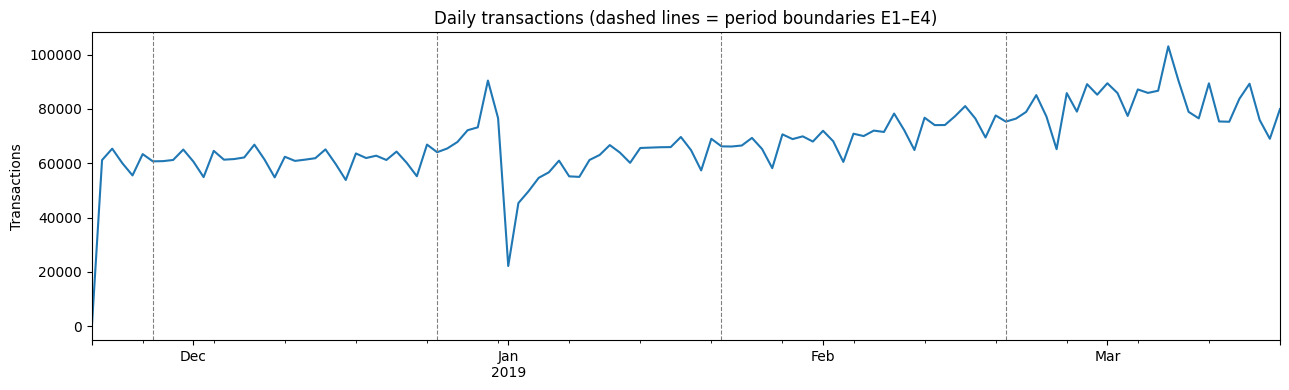

In [7]:
daily = pd.concat(daily_parts).groupby(level=0).sum().sort_index()
last_purchase = pd.concat(last_parts)
print("First day with purchases:", daily.index.min().date(), "| last:", daily.index.max().date())

fig, ax = plt.subplots(figsize=(13, 4))
daily.plot(ax=ax)
for b in PERIOD_BOUNDS:
    ax.axvline(b, color="grey", ls="--", lw=0.8)
ax.set(title="Daily transactions (dashed lines = period boundaries E1–E4)", xlabel="", ylabel="Transactions")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_daily_transactions.png", dpi=130)
plt.show()

The history begins on 2018-11-21 (that first day is nearly empty), so E1 starts on 2018-11-27 to leave four full, equal 28-day periods
ending at the 2019-03-19 cutoff. The upward trend in daily transactions is examined in notebook 02: part of it is new loyalty-card
holders entering the data, not existing customers shopping more.

In [8]:
tx_in_window = pd.concat(tx_parts, ignore_index=True)
del tx_parts
print(f"Transactions in E1–E4: {len(tx_in_window):,}")
print(tx_in_window["period"].map(dict(enumerate(PERIODS))).value_counts().sort_index())
tx_in_window[["purchase_sum", "quantity", "unique_products"]].astype(float).describe().round(2)

Transactions in E1–E4: 7,739,710


period
E1    1717247
E2    1748780
E3    1976528
E4    2297155
Name: count, dtype: int64


,purchase_sum,quantity,unique_products
count,7739710.00,7739710.00,7739710.00
mean,428.92,7.10,5.69
std,490.93,11.26,5.01
min,0.00,0.00,1.00
25%,140.29,3.00,2.00
50%,282.00,5.00,4.00
75%,533.17,9.00,7.00
max,35149.04,18457.00,116.00


In [9]:
# Selection check: every competition customer purchases close to the cutoff
days_before_cutoff = (CUTOFF_DATE - last_purchase).dt.days
print("Days between last purchase and cutoff:")
print(days_before_cutoff.describe(percentiles=[.25, .5, .75, .95, .99]).round(1))

Days between last purchase and cutoff:
count    400162.0
mean          5.8
std           5.7
min           0.0
25%           1.0
50%           4.0
75%           9.0
95%          18.0
99%          21.0
max          22.0
Name: datetime, dtype: float64


Every customer bought something within 22 days of the cutoff. The sample is therefore **conditioned on recent activity**:
differences between E4 and earlier periods are partly built into how the sample was drawn, not purely behavioral change.

## 5 · Customer-period behavior

For each customer and period:

| Feature | Definition |
|---|---|
| `transactions` | number of baskets |
| `total_spend` | sum of basket `purchase_sum` |
| `avg_basket_spend` | mean basket `purchase_sum` |
| `total_quantity` | sum of item quantities |
| `avg_quantity` | mean items per basket |
| `avg_unique_products` | mean distinct products per basket |

Periods with no purchases get 0 for every feature (so "average basket" = 0 there means *no basket*, not a cheap one).
`card_issued` records whether the customer's loyalty card existed at the start of the period: a 0-transaction period before the card
existed means *not observable*, not *inactive*.

In [10]:
cp = pd.concat(cp_parts)
del cp_parts
category_lines = pd.concat(cat_parts).reset_index()
del cat_parts

grid = pd.MultiIndex.from_product([np.arange(len(client_index), dtype=np.int32), np.arange(4, dtype=np.int8)],
                                  names=["client", "period"])
BEHAVIOR = list(cp.columns)
customer_period = cp.reindex(grid, fill_value=0).reset_index()
customer_period[BEHAVIOR] = customer_period[BEHAVIOR].astype(float)

customer_period["client_id"] = client_index[customer_period["client"].to_numpy()].to_numpy()
customer_period["period_name"] = np.array(PERIODS)[customer_period["period"].to_numpy()]

issue_date = clients.set_index("client_id")["first_issue_date"].reindex(client_index).to_numpy()
period_start = PERIOD_BOUNDS.values[customer_period["period"].to_numpy()]
customer_period["card_issued"] = issue_date[customer_period["client"].to_numpy()] < period_start

print(customer_period.shape)
summary = customer_period.groupby("period_name").agg(
    mean_transactions=("transactions", "mean"),
    zero_tx_share=("transactions", lambda x: (x == 0).mean()),
    card_not_yet_issued=("card_issued", lambda x: 1 - x.mean()))
summary.round(3)

(1600648, 11)


,mean_transactions,zero_tx_share,card_not_yet_issued
period_name,,,
E1,4.291,0.213,0.112
E2,4.370,0.182,0.077
E3,4.939,0.139,0.048
E4,5.741,0.000,0.020


## 6 · Wide table and temporal change features

One row per customer, one column per feature × period (24 columns). For four core features we add:

- **trend** = (E3 − E1) / 2 — average change per period over the history window E1–E3;
- **historical mean** = mean of E1, E2, E3;
- **recent deviation** = E4 − historical mean — how far the latest period sits from the customer's own past.

Differences rather than percentage changes, because many customers have 0 in an early period.

In [11]:
wide = customer_period.pivot(index="client_id", columns="period_name", values=BEHAVIOR)
wide.columns = [f"{f}_{p}" for f, p in wide.columns]
wide = wide[[f"{f}_{p}" for f in BEHAVIOR for p in PERIODS]].reset_index()

CHANGE_FEATURES = ["transactions", "total_spend", "avg_basket_spend", "total_quantity"]
for f in CHANGE_FEATURES:
    wide[f"{f}_trend"] = (wide[f"{f}_E3"] - wide[f"{f}_E1"]) / 2
for f in CHANGE_FEATURES:
    wide[f"{f}_historical_mean"] = wide[[f"{f}_E1", f"{f}_E2", f"{f}_E3"]].mean(axis=1)
    wide[f"{f}_recent_deviation"] = wide[f"{f}_E4"] - wide[f"{f}_historical_mean"]

print(wide.shape)
wide[[c for c in wide.columns if c.startswith("transactions")]].head()

(400162, 37)


,transactions_E1,transactions_E2,transactions_E3,transactions_E4,transactions_trend,transactions_historical_mean,transactions_recent_deviation
0,2.0,0.0,0.0,2.0,-1.0,0.666667,1.333333
1,10.0,4.0,10.0,8.0,0.0,8.000000,0.000000
2,1.0,2.0,4.0,1.0,1.5,2.333333,-1.333333
3,3.0,4.0,3.0,6.0,0.0,3.333333,2.666667
4,3.0,4.0,2.0,1.0,-0.5,3.000000,-2.000000


## 7 · Category composition and category drift

For each customer-period, the **category mix** is the share of product lines falling in each `level_2` category (≈43 categories).

**Jensen–Shannon (JS) distance** compares two mixes: 0 = identical, 1 = no overlap (base-2 logs). It is symmetric and stays finite when a
category is absent from one of the two mixes, which plain KL divergence does not. It is undefined (NaN) if either period has no purchases.

Computed for every adjacent pair (E1→E2, E2→E3, E3→E4), for E1→E3, and **history→E4**, where the historical mix is the
average of the customer's *active* E1–E3 mixes (not divided by three blindly).

In [12]:
n_clients, n_cats = len(client_index), len(level2_names)
mixes = {}
for k, p in enumerate(PERIODS):
    sub = category_lines[category_lines["period"] == k]
    counts = np.zeros((n_clients, n_cats))
    counts[sub["client"].to_numpy(), sub["level_2"].to_numpy()] = sub["line_count"].to_numpy()
    totals = counts.sum(axis=1, keepdims=True)
    mixes[p] = np.divide(counts, totals, out=np.zeros_like(counts), where=totals > 0)

def js_distance_rows(P, Q):
    """Row-wise Jensen-Shannon distance (base 2). NaN where either row is empty."""
    valid = (P.sum(axis=1) > 0) & (Q.sum(axis=1) > 0)
    out = np.full(P.shape[0], np.nan)
    Pv, Qv = P[valid], Q[valid]
    Mv = 0.5 * (Pv + Qv)
    with np.errstate(divide="ignore", invalid="ignore"):
        kl_pm = np.where(Pv > 0, Pv * np.log2(Pv / Mv), 0).sum(axis=1)
        kl_qm = np.where(Qv > 0, Qv * np.log2(Qv / Mv), 0).sum(axis=1)
    out[valid] = np.sqrt(0.5 * (kl_pm + kl_qm))
    return out

history = np.stack([mixes["E1"], mixes["E2"], mixes["E3"]], axis=1)
history_active = history.sum(axis=2) > 0
history_periods_active = history_active.sum(axis=1)
historical_mix = history.sum(axis=1)
has_history = history_periods_active > 0
historical_mix[has_history] /= history_periods_active[has_history, None]

category_drift = pd.DataFrame({
    "client_id": client_index,
    "category_drift_E1_E2": js_distance_rows(mixes["E1"], mixes["E2"]),
    "category_drift_E2_E3": js_distance_rows(mixes["E2"], mixes["E3"]),
    "category_drift_E3_E4": js_distance_rows(mixes["E3"], mixes["E4"]),
    "category_drift_E1_E3": js_distance_rows(mixes["E1"], mixes["E3"]),
    "category_drift_history_E4": js_distance_rows(historical_mix, mixes["E4"]),
    "history_periods_active": history_periods_active,
})
del history, mixes

lines_by_period = (category_lines.groupby(["client", "period"])["line_count"].sum()
                                 .unstack(fill_value=0).reindex(range(n_clients), fill_value=0))
for k, p in enumerate(PERIODS):
    category_drift[f"category_lines_{p}"] = lines_by_period[k].to_numpy()
category_drift["historical_category_lines"] = category_drift[["category_lines_E1", "category_lines_E2", "category_lines_E3"]].sum(axis=1)

drift_cols = [c for c in category_drift.columns if c.startswith("category_drift")]
category_drift[drift_cols].describe().T.round(3).assign(missing=category_drift[drift_cols].isna().sum())

,count,mean,std,min,25%,50%,75%,max,missing
category_drift_E1_E2,286301.0,0.504,0.182,0.0,0.368,0.476,0.616,1.0,113861
category_drift_E2_E3,301368.0,0.503,0.178,0.0,0.371,0.474,0.611,1.0,98794
category_drift_E3_E4,344535.0,0.492,0.182,0.0,0.357,0.462,0.602,1.0,55627
category_drift_E1_E3,288613.0,0.508,0.178,0.0,0.376,0.480,0.615,1.0,111549
category_drift_history_E4,379112.0,0.466,0.174,0.0,0.336,0.435,0.568,1.0,21050


## 8 · Measurement check: category drift depends on how much history we observe

A JS distance computed from few purchase lines is noisy: with 5 lines, the mix jumps around even if preferences are fixed.
If drift is larger for customers with *less* history, part of "drift" is sampling noise, not changed preferences.

In [13]:
check = category_drift.dropna(subset=["category_drift_history_E4"]).copy()
print("Correlation(history→E4 drift, historical lines):",
      round(check["category_drift_history_E4"].corr(check["historical_category_lines"]), 4))

check["drift_quartile"] = pd.qcut(check["category_drift_history_E4"], 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
check.groupby("drift_quartile", observed=True).agg(
    customers=("client_id", "size"),
    mean_drift=("category_drift_history_E4", "mean"),
    median_history_lines=("historical_category_lines", "median"),
    mean_history_periods=("history_periods_active", "mean")).round(3)

Correlation(history→E4 drift, historical lines): -0.5395


,customers,mean_drift,median_history_lines,mean_history_periods
drift_quartile,,,,
Q1 low,94778,0.274,126.0,2.849
Q2,94778,0.385,77.0,2.748
Q3,94778,0.496,48.0,2.580
Q4 high,94778,0.710,24.0,2.234


Customers in the highest-drift quartile have far less history (median lines roughly 5× lower than the lowest-drift quartile).
**Raw category drift is strongly confounded with observation depth.** Any analysis using it must compare customers with similar history
depth (done in notebook 02). The same applies to the per-pair drift measures, which rest on even fewer lines per period.

## 9 · Save processed tables

| File | Rows | Contents |
|---|---|---|
| `customer_period.parquet` | 400,162 × 4 periods | long-format behavior per customer-period, card status, category line count |
| `category_drift.parquet` | 400,162 | all JS drift measures and history depth, every customer |
| `model_data.parquet` | 200,039 | uplift-train customers: treatment, outcome, wide behavior, change features, category drift |

`model_data.parquet` keeps the same columns as before, except: the whole-dataset-standardized instability columns
(`*_recent_deviation_z`, `behavioral_instability`, `instability_quartile`) are no longer saved (they leaked validation/test statistics; notebooks 02–04
recompute instability from training data), and `category_drift_E1_E2` / `category_drift_E2_E3` are new.

In [14]:
customer_period["category_lines"] = lines_by_period.to_numpy()[customer_period["client"].to_numpy(), customer_period["period"].to_numpy()]
customer_period_out = customer_period[["client_id", "period_name", "card_issued", "category_lines"] + BEHAVIOR] \
    .rename(columns={"period_name": "period"})
customer_period_out.to_parquet(PROCESSED_DIR / "customer_period.parquet", index=False)

drift_out = category_drift.drop(columns=[f"category_lines_{p}" for p in PERIODS])
drift_out.to_parquet(PROCESSED_DIR / "category_drift.parquet", index=False)

model_data = (uplift_train
              .merge(wide, on="client_id", how="left")
              .merge(drift_out[["client_id", "category_drift_E1_E3", "category_drift_E3_E4", "category_drift_history_E4",
                                "category_drift_E1_E2", "category_drift_E2_E3",
                                "history_periods_active", "historical_category_lines"]],
                     on="client_id", how="left"))
assert len(model_data) == len(uplift_train) and model_data[wide.columns].notna().all().all()
model_data.to_parquet(PROCESSED_DIR / "model_data.parquet", index=False)

for f in ["customer_period.parquet", "category_drift.parquet", "model_data.parquet"]:
    print(f"{f:25s} {(PROCESSED_DIR / f).stat().st_size / 1e6:6.1f} MB")
print("model_data:", model_data.shape)

customer_period.parquet     31.2 MB
category_drift.parquet      18.3 MB
model_data.parquet          31.7 MB
model_data: (200039, 46)
